In [1]:
import pandas as pd
from visualization import load_results_to_df, get_task, aggregate_seeds, performance_table, scatter_plot, cost_scatter_grid

In [2]:
baseline1 = load_results_to_df("results/final_results.jsonl", stop_line=60)
tuning = load_results_to_df("results/final_results.jsonl", start_line=60, stop_line=110)
baseline2 = load_results_to_df("results/final_results.jsonl", start_line=110, stop_line=161)
baseline3 = load_results_to_df("results/final_results.jsonl", start_line=161, stop_line=None)

for df in [tuning, baseline1, baseline2, baseline3]:
    df['task'] = df.apply(get_task, axis=1)
    df['performance'] = df['dev_accuracy'].combine_first(df['dev_chrf'])
    df.drop(df[df['task'] == 'sonnet_beam'].index, inplace=True)
    df["time_per_epoch"] = df["train_time"] / (df["best_epoch"] + df["patience"])

agg = aggregate_seeds([baseline1, baseline2, baseline3])

In [3]:
tuning[["task", "performance", "model_size", "fine_tune_mode"]]

,task,performance,model_size,fine_tune_mode
0,sst,0.507720,gpt2,full-model
1,sst,0.550409,gpt2-medium,full-model
2,sst,0.500454,gpt2-large,last-linear-layer
3,sst,0.548592,gpt2-large,lora
4,cfimdb,0.873469,gpt2-medium,last-linear-layer
5,cfimdb,0.975510,gpt2-medium,lora
6,cfimdb,0.963265,gpt2-medium,full-model
7,cfimdb,0.885714,gpt2-large,last-linear-layer
8,cfimdb,0.971429,gpt2-large,lora
9,cfimdb,0.861224,gpt2-medium,last-linear-layer


In [6]:

agg["params_percent"] = 100 * agg["trainable_params"] / agg["total_params"]
agg[["mem_alloc_mean", "trainable_params", "params_percent", "time_per_epoch_mean",  "model_size", "fine_tune_mode", "task"]]
agg["time_per_epoch_mean"]
agg[["best_epoch_time_mean", "best_epoch_time_std", "best_epoch_mean", "best_epoch_std", "model_size", "fine_tune_mode", "task"]]


,best_epoch_time_mean,best_epoch_time_std,best_epoch_mean,best_epoch_std,model_size,fine_tune_mode,task
0,9.987761,5.312029,4.333333,2.886751,gpt2,full-model,cfimdb
1,25.114885,7.974764,6.333333,2.516611,gpt2,full-model,paraphrase
2,5.758280,2.263339,14.000000,6.244998,gpt2,full-model,sonnet_top_p
3,6.293340,1.558761,4.333333,1.154701,gpt2,full-model,sst
4,17.328353,11.220852,2.333333,2.081666,gpt2-medium,full-model,cfimdb
5,40.859475,22.634289,2.666667,2.081666,gpt2-medium,full-model,paraphrase
6,11.053438,4.432127,13.666667,6.110101,gpt2-medium,full-model,sonnet_top_p
7,14.165973,0.626692,3.000000,0.000000,gpt2-medium,full-model,sst
8,7.874601,3.694699,5.666667,3.511885,gpt2,last-linear-layer,cfimdb
9,6.433459,3.435113,4.333333,3.214550,gpt2,last-linear-layer,paraphrase


In [ ]:
for df in [baseline1, baseline2, baseline3]:
    print(df.shape)
    print()
    performance_table(df=df)

(29, 64)

               Mode (LR)   Size Sentiment (SST) Sentiment (CFIMDB) Paraphrase Sonnet (Top P) Sonnet (Beam Search)
Last linear layer (1e-3)  small            47.9               88.6       72.3              -                    -
                         medium            49.1               86.1       74.1              -                    -
                          large            50.5               90.6       76.5              -                    -
             LoRA (1e-4)  small            51.6               98.4       84.2           26.7                    -
                         medium            55.8               97.1       86.7           26.7                    -
                          large            55.3               96.7       87.1           27.4                    -
       Full model (1e-5)  small            51.0               98.8       84.5           26.5                    -
                         medium            55.6               98.0       85.7 

In [ ]:
print(agg.shape)
performance_table(mean_std_df=agg)

(29, 15)
               Mode (LR)   Size Sentiment (SST) Sentiment (CFIMDB) Paraphrase Sonnet (Top P) Sonnet (Beam Search)
Last linear layer (1e-3)  small      47.4 ± 0.5         86.0 ± 2.5 71.0 ± 1.5              -                    -
                         medium      49.1 ± 0.6         86.3 ± 0.2 74.5 ± 0.3              -                    -
                          large      50.4 ± 0.3         90.6 ± 0.0 76.5 ± 0.2              -                    -
             LoRA (1e-4)  small      51.6 ± 0.1         97.7 ± 0.6 84.4 ± 0.3     26.3 ± 0.5                    -
                         medium      55.2 ± 0.5         97.6 ± 0.4 86.3 ± 0.3     26.9 ± 0.2                    -
                          large      54.9 ± 0.5         97.3 ± 0.6 87.2 ± 0.1     27.0 ± 0.4                    -
       Full model (1e-5)  small      50.1 ± 0.9         98.0 ± 0.7 84.5 ± 0.1     26.3 ± 0.5                    -
                         medium      54.8 ± 1.1         97.7 ± 0.5 85.8 ± 0.4  

# Acc vs Params

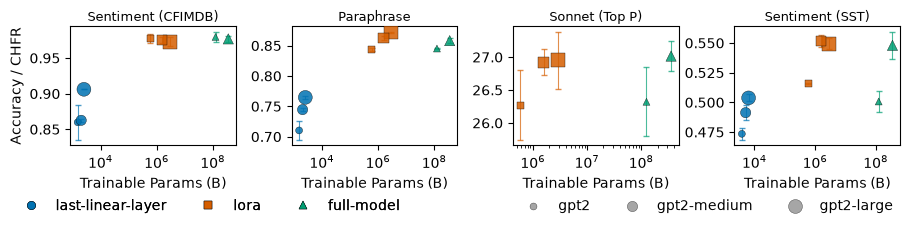

In [ ]:
scatter_plot(
    agg, 
    metric1=("Trainable Params (B)", "trainable_params"),
    metric2=("Accuracy / CHFR", "mean", "std"),
    log_scale=True,
)

# Acc vs Memory

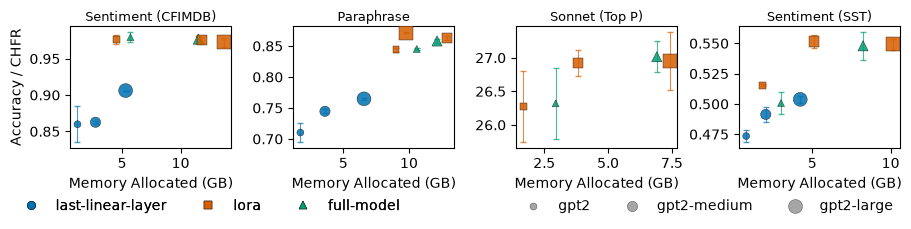

In [ ]:
scatter_plot(
    agg, 
    metric1=("Memory Allocated (GB)", "mem_alloc_mean"),
    metric2=("Accuracy / CHFR", "mean", "std"),
    log_scale=False,
)

# Acc vs Time

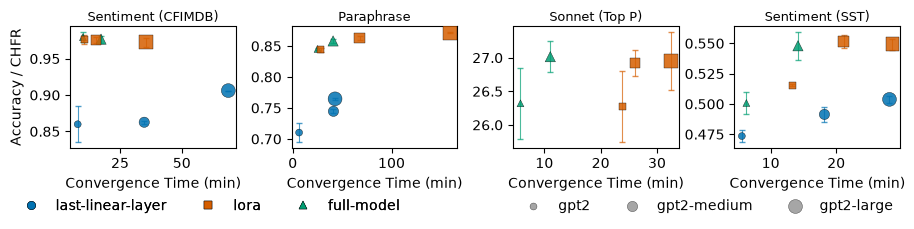

In [ ]:
scatter_plot(
    agg, 
    metric1=("Convergence Time (min)", "best_epoch_time_mean"),
    metric2=("Accuracy / CHFR", "mean", "std"),
    log_scale=False,
)

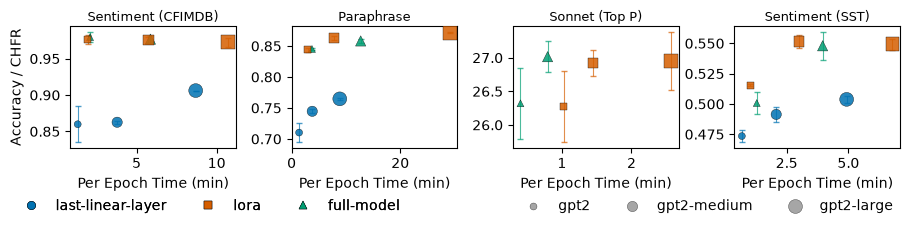

In [8]:
scatter_plot(
    agg, 
    metric1=("Per Epoch Time (min)", "time_per_epoch_mean"),
    metric2=("Accuracy / CHFR", "mean", "std"),
    log_scale=False,
)

# Combined

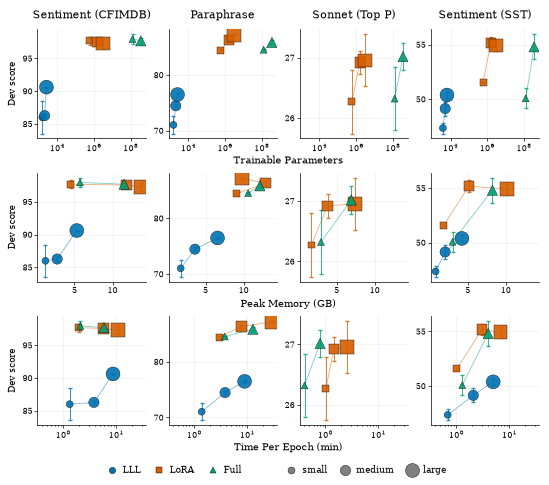

In [ ]:

# (x label, col in df, log scale)
COST_ROWS = [
    ("Trainable Parameters", "trainable_params", True),
    ("Peak Memory (GB)", "mem_alloc_mean", False),
    ("Time Per Epoch (min)", "time_per_epoch_mean",True),
]

cost_scatter_grid(agg, rows=COST_ROWS, filepath="figures/cost_combined.pdf")